In [1]:
#cell 1: quét video Hand và Bonus, gom khối theo khoảng nghỉ giữa các lần quay
import cv2, numpy as np, pandas as pd
from pathlib import Path
BASE = Path(r"C:\Users\Acer Nitro 5 Tiger\Downloads\Data_321")
OUT = BASE / "leak_check"; OUT.mkdir(exist_ok=True)
NGUON = ["Dataset_hand", "Dataset_bonus"]
GAP = 300  # giây: nghỉ lâu hơn mức này thì tính là khối mới (tham số tự đặt)
rows = []
for ng in NGUON:
    for lop in ["rock", "paper", "scissors"]:
        for p in sorted((BASE / ng / lop).glob("*.mp4")):
            rows.append(dict(nguon=ng, lop=lop, fn=p.stem, path=str(p)))
df = pd.DataFrame(rows)
df["t"] = pd.to_datetime(df.fn.str[4:18], format="%Y%m%d%H%M%S")
df = df.sort_values(["nguon", "t"]).reset_index(drop=True)
df["gap"] = df.groupby("nguon").t.diff().dt.total_seconds()
df["khoi"] = (df.gap.fillna(1e9) > GAP).groupby(df.nguon).cumsum().astype(int)
df["nhom"] = df.nguon + "_k" + df.khoi.astype(str)
print(df.groupby("nguon").size().to_dict(), "(manifest: Dataset_hand 81, Dataset_bonus 90)")
bt = df.groupby("nhom").agg(nguon=("nguon", "first"), khoi=("khoi", "first"), bat_dau=("t", "min"), ket_thuc=("t", "max"), n=("fn", "size"),
      rock=("lop", lambda s: (s == "rock").sum()), paper=("lop", lambda s: (s == "paper").sum()), scissors=("lop", lambda s: (s == "scissors").sum()))
print(bt.sort_values(["nguon", "khoi"]).drop(columns=["nguon", "khoi"]).to_string())

{'Dataset_bonus': 90, 'Dataset_hand': 81} (manifest: Dataset_hand 81, Dataset_bonus 90)
                             bat_dau            ket_thuc   n  rock  paper  scissors
nhom                                                                               
Dataset_bonus_k1 2026-10-24 17:18:23 2026-10-24 17:34:18  12     4      4         4
Dataset_bonus_k2 2026-10-25 00:21:08 2026-10-25 00:41:12  18     6      6         6
Dataset_bonus_k3 2026-10-25 11:14:58 2026-10-25 11:50:26  30    10     10        10
Dataset_bonus_k4 2026-10-25 12:35:19 2026-10-25 12:38:05   3     1      1         1
Dataset_bonus_k5 2026-10-25 12:44:02 2026-10-25 13:11:14  15     5      5         5
Dataset_bonus_k6 2026-10-25 17:31:21 2026-10-25 17:45:02  12     4      4         4
Dataset_hand_k1  2026-10-02 07:38:19 2026-10-02 07:41:20   3     1      1         1
Dataset_hand_k2  2026-10-02 07:50:23 2026-10-02 08:19:26  27     9      9         9
Dataset_hand_k3  2026-10-02 11:09:35 2026-10-02 11:10:59   3     1      

In [2]:
#cell 2: lấy 3 khung (25%, 50%, 75%) mỗi clip và tính histogram màu
def frames(p, pos=(0.25, 0.5, 0.75)):
    c = cv2.VideoCapture(p); n = int(c.get(7)); out = []
    for q in pos:
        c.set(1, int(n * q)); ok, f = c.read()
        if ok: out.append(f)
    c.release(); return out
def hist(fs):
    hs = []
    for f in fs:
        h = cv2.calcHist([cv2.resize(f, (160, 90))], [0, 1, 2], None, [8, 8, 8], [0, 256] * 3).flatten()
        hs.append(h / h.sum())
    return np.mean(hs, 0).astype("float32")
F = [frames(p) for p in df.path]
H = np.array([hist(f) for f in F]); n = len(df)
D = np.array([[cv2.compareHist(H[i], H[j], cv2.HISTCMP_BHATTACHARYYA) for j in range(n)] for i in range(n)])
print("xong", n, "clip")

xong 171 clip


In [3]:
#cell 3: so độ giống giữa các khối (nhỏ = giống nhau hơn; đường chéo = trong cùng khối)
for ng in NGUON:
    idx = np.where(df.nguon == ng)[0]; g = df.nhom.values[idx]; Ds = D[np.ix_(idx, idx)]
    names = sorted(set(g), key=lambda x: int(x.split("_k")[1])); lab = [x.split("_")[-1] for x in names]
    def tb(a, b):
        s = Ds[np.ix_(g == a, g == b)]; k = len(s)
        if a == b: return s.sum() / (k * (k - 1)) if k > 1 else np.nan
        return s.mean()
    print("\n", ng, ": khoảng cách trung bình giữa các khối")
    print(pd.DataFrame([[tb(a, b) for b in names] for a in names], index=lab, columns=lab).round(3))
    nn = (Ds + np.eye(len(idx)) * 9).argmin(1)
    print(ng, ": clip giống nhất với mỗi clip nằm ở khối nào (hàng = khối của clip, cột = khối của clip giống nhất)")
    print(pd.crosstab(pd.Series(g, name="khoi").str.split("_").str[-1], pd.Series(g[nn], name="giong_nhat").str.split("_").str[-1]))


 Dataset_hand : khoảng cách trung bình giữa các khối
       k1     k2     k3     k4     k5     k6     k7
k1  0.059  0.514  0.491  0.649  0.518  0.625  0.617
k2  0.514  0.173  0.128  0.521  0.341  0.442  0.447
k3  0.491  0.128  0.056  0.510  0.329  0.465  0.470
k4  0.649  0.521  0.510  0.347  0.407  0.468  0.476
k5  0.518  0.341  0.329  0.407  0.141  0.362  0.365
k6  0.625  0.442  0.465  0.468  0.362  0.049  0.080
k7  0.617  0.447  0.470  0.476  0.365  0.080  0.050
Dataset_hand : clip giống nhất với mỗi clip nằm ở khối nào (hàng = khối của clip, cột = khối của clip giống nhất)
giong_nhat  k1  k2  k3  k4  k5  k6  k7
khoi                                  
k1           3   0   0   0   0   0   0
k2           0  25   2   0   0   0   0
k3           0   3   0   0   0   0   0
k4           0   0   0  12   0   0   0
k5           0   0   0   0   6   0   0
k6           0   0   0   0   0   5   1
k7           0   0   0   0   0   0  24

 Dataset_bonus : khoảng cách trung bình giữa các khối
       k1 

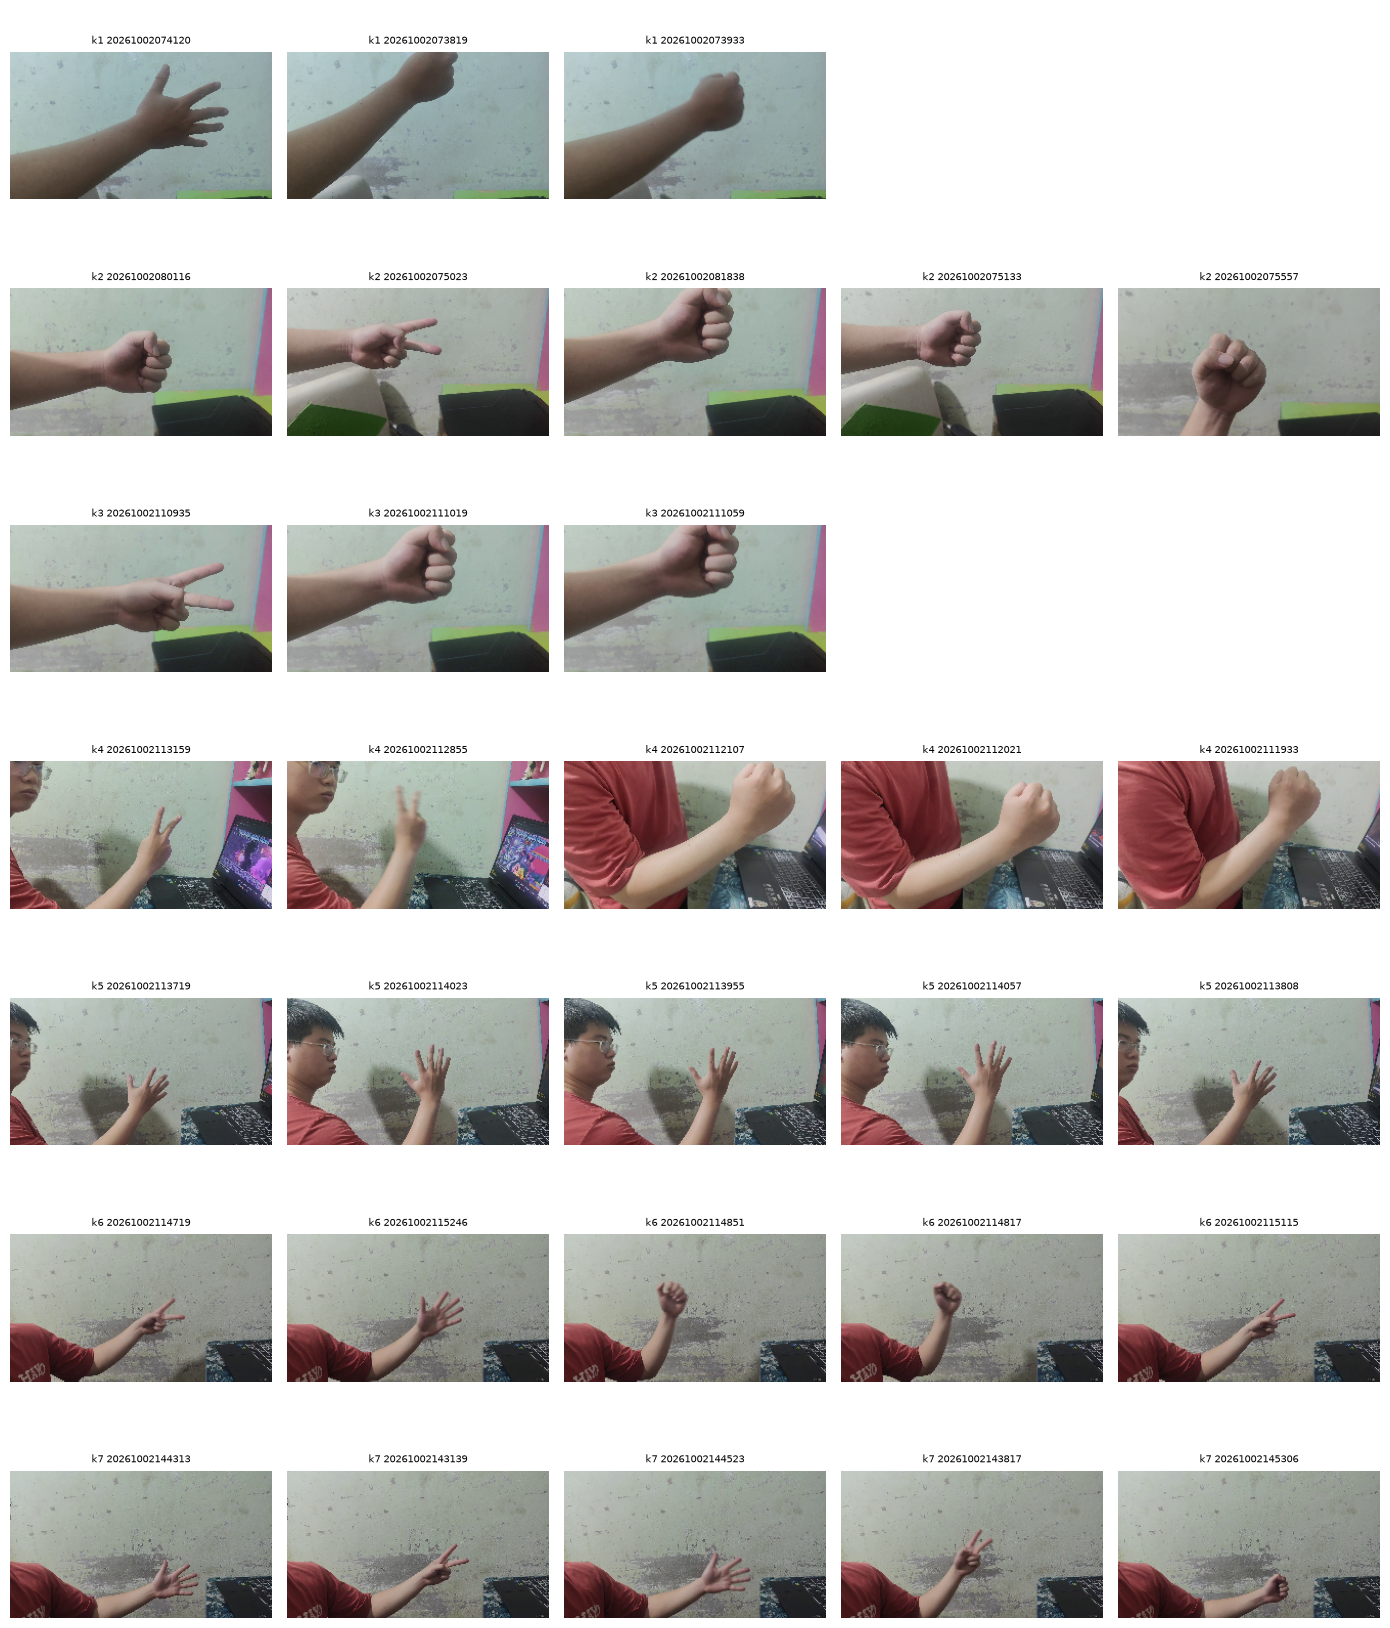

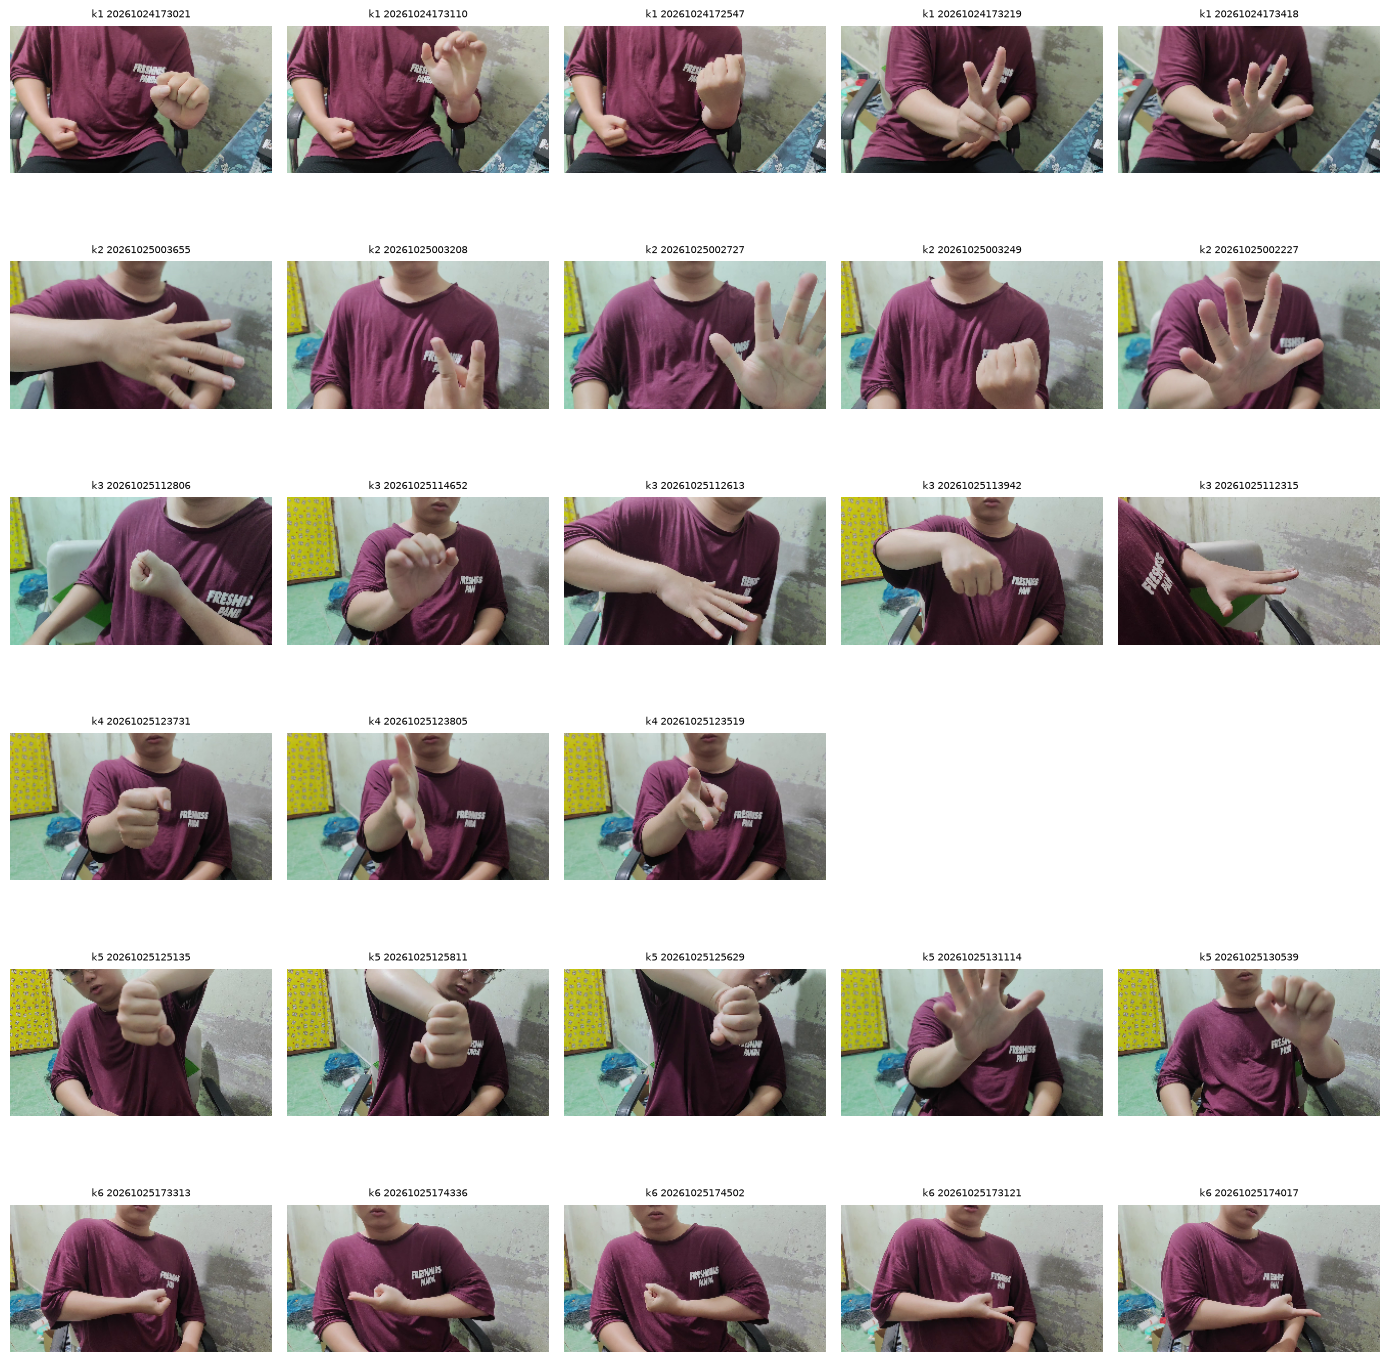

Đã lưu vào C:\Users\Acer Nitro 5 Tiger\Downloads\Data_321\leak_check


In [4]:
#cell 4: xuất bảng CSV và ảnh ghép khung mẫu từng khối để nhìn bằng mắt
import matplotlib.pyplot as plt
df.drop(columns=["path"]).to_csv(OUT / "handbonus_check.csv", index=False, encoding="utf-8-sig")
K = 5; rng = np.random.default_rng(0)
for ng in NGUON:
    sub = df[df.nguon == ng]; names = sorted(sub.nhom.unique(), key=lambda x: int(x.split("_k")[1]))
    fig, ax = plt.subplots(len(names), K, figsize=(2.8 * K, 2.4 * len(names)), squeeze=False)
    for r, a in enumerate(names):
        idx = rng.choice(np.where(df.nhom.values == a)[0], min(K, (df.nhom.values == a).sum()), replace=False)
        for c in range(K):
            ax[r, c].axis("off")
            if c < len(idx) and len(F[idx[c]]) > 1:
                f = F[idx[c]][1]; w = int(f.shape[1] * 144 / f.shape[0])
                ax[r, c].imshow(cv2.cvtColor(cv2.resize(f, (w, 144)), cv2.COLOR_BGR2RGB))
                ax[r, c].set_title(a.split("_")[-1] + " " + df.fn[idx[c]][4:18], fontsize=7)
    plt.tight_layout(); plt.savefig(OUT / f"{ng}_mau.png", dpi=110); plt.show()
print("Đã lưu vào", OUT)